# Molecular toxicity shortcut test: motif–label conflict and mitigation

## Why this is the next experiment

The earlier notebook found that a Random Forest could distinguish positive from negative Tox21 assay outcomes among held-out molecules that shared a structural motif (mean within-motif ROC-AUC 0.663 across 41 eligible motif–assay groups). That supports **context-sensitive prediction**, but does not establish shortcut learning.

This notebook tests a more direct question:

> When a motif's relationship with an assay label in the training data conflicts with the held-out molecule's observed label, does the model perform worse—and can reducing that training correlation improve conflict-case predictions without substantially damaging overall performance?

### What this notebook compares

1. **Full molecular model:** Random Forest trained on Morgan fingerprints.
2. **Motif-only baseline:** predicts from the candidate motif's training-fold association with the label.
3. **Motif-associated fingerprint-bit ablation:** identifies Morgan bit IDs produced by motif-overlapping atom environments in training-fold molecules, then masks those bit columns in both training and held-out fingerprints.
4. **Correlation-balanced model:** for one nominated motif, uses capped sample weights to make the four motif-presence × label groups more balanced in the training fold.

All predictions are out-of-fold. Molecules are split by Bemis–Murcko scaffold, and the motif–label association is estimated from the training fold only. Test labels are used only to score and define evaluation subgroups—not to train the model or choose the cue direction.

### Important scientific limits

- The candidate motifs, especially **alkyl halide**, were selected after looking at preliminary results. Analyses on Tox21 are therefore exploratory, not confirmatory.
- A worse score on conflict examples is evidence of brittleness associated with a training correlation; it is not by itself proof of causal shortcut reliance.
- Both interventions are imperfect. Correlation balancing can remove real chemical signal; Morgan bit masking is approximate because hashed bits can represent more than one chemical environment. We must report overall performance and conflict performance together.
- The Morgan-fingerprint model is a baseline, not a graph neural network. Strong claims should be replicated with other representations and an independent dataset or genuinely held-out endpoint.

The default settings are intended to be understandable and practical. Read the interpretation cells before making a claim for a paper.

## 1. Install and import dependencies

Run this cell in Jupyter if RDKit or scikit-learn is missing.

In [ ]:
%pip install -q pandas numpy scikit-learn rdkit matplotlib requests

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    roc_auc_score, log_loss, brier_score_loss, balanced_accuracy_score
)

RANDOM_STATE = 20261017
DATA_PATH = None  # Optional local path, e.g. "tox21.csv"
TOX21_URLS = [
    "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/tox21.csv.gz",
    "https://raw.githubusercontent.com/deepchem/deepchem/master/datasets/tox21.csv",
]

N_SPLITS = 5
N_ESTIMATORS = 200
MIN_TRAIN_MOTIF_N = 25       # min training rows with motif absent AND present
MIN_ASSOCIATION_DELTA = 0.10 # abs(P(y=1|motif)-P(y=1|no motif)) needed to define a cue
MIN_EVAL_CLASS_COUNT = 10    # AUC only if subgroup has at least this many examples per class
MIN_BALANCE_CELL_N = 10      # each motif x label cell needed for mitigation
MAX_SAMPLE_WEIGHT = 5.0      # cap inverse-frequency weights to avoid rare-cell domination
MITIGATION_MOTIF = "alkyl_halide"  # chosen after preliminary results; explicitly exploratory

print("Imports ready. RDKit:", __import__("rdkit").__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 42.5 MB/s eta 0:00:00
Imports ready. RDKit: 2026.09.1


## 2. Load Tox21 and prepare unique molecules

For duplicate canonical SMILES, labels with a single consistent observed value are kept. If duplicate records disagree for an assay, that molecule’s label for that assay is marked missing rather than arbitrarily choosing one of the labels. This makes the handling of duplicate structures explicit.

In [ ]:
data = None
load_errors = []

if DATA_PATH and os.path.exists(DATA_PATH):
    try:
        data = pd.read_csv(DATA_PATH)
        print(f"Loaded local file: {DATA_PATH} | shape={data.shape}")
    except Exception as exc:
        load_errors.append(f"Local file error: {type(exc).__name__}: {exc}")

if data is None:
    for url in TOX21_URLS:
        try:
            print("Trying:", url)
            data = pd.read_csv(url)
            print(f"Loaded remote dataset | shape={data.shape}")
            break
        except Exception as exc:
            load_errors.append(f"{url}: {type(exc).__name__}: {exc}")

if data is None:
    print("Tox21 could not be loaded. Set DATA_PATH to a local CSV and rerun this cell.")
    for err in load_errors:
        print(" -", err)
    raise RuntimeError("Tox21 dataset unavailable")

if "smiles" not in data.columns:
    raise ValueError("Expected a 'smiles' column in the Tox21 CSV.")

# Tox21 assay columns are numeric/binary; exclude identifiers and other metadata.
label_cols = []
for col in data.columns:
    if col in {"smiles", "mol_id", "canonical_smiles"}:
        continue
    values = data[col].dropna()
    if len(values) and values.astype(str).isin(["0", "1", "0.0", "1.0"]).all():
        label_cols.append(col)
if not label_cols:
    raise ValueError("Could not identify binary assay columns.")

valid = []
invalid_smiles = 0
for _, row in data.iterrows():
    mol = Chem.MolFromSmiles(str(row["smiles"]))
    if mol is None:
        invalid_smiles += 1
        continue
    valid.append((Chem.MolToSmiles(mol), row[label_cols].to_dict()))

records = []
conflicting_duplicate_labels = {c: 0 for c in label_cols}
for canonical, group in pd.DataFrame(valid, columns=["canonical_smiles", "labels"]).groupby("canonical_smiles", sort=False):
    out = {"canonical_smiles": canonical}
    for col in label_cols:
        vals = [v.get(col) for v in group["labels"]]
        vals = [int(float(v)) for v in vals if pd.notna(v) and str(v) in {"0", "1", "0.0", "1.0"}]
        uniq = set(vals)
        if len(uniq) == 1:
            out[col] = next(iter(uniq))
        else:
            out[col] = np.nan
            if len(uniq) > 1:
                conflicting_duplicate_labels[col] += 1
    records.append(out)

clean = pd.DataFrame(records)
mols = [Chem.MolFromSmiles(s) for s in clean["canonical_smiles"]]

print(f"Source rows: {len(data):,}")
print(f"Invalid SMILES excluded: {invalid_smiles:,}")
print(f"Unique valid canonical structures: {len(clean):,}")
print("Assays:", label_cols)
print("Assay-level structures with conflicting duplicate labels (marked missing):")
display(pd.Series(conflicting_duplicate_labels, name="conflicting_duplicate_structures").to_frame())

Trying: https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/tox21.csv.gz
Loaded remote dataset | shape=(7831, 14)


[21:35:14] WARNING: not removing hydrogen atom without neighbors
[21:35:15] Explicit valence for atom # 8 Al, 6, is greater than permitted
[21:35:16] Explicit valence for atom # 3 Al, 6, is greater than permitted
[21:35:16] Explicit valence for atom # 4 Al, 6, is greater than permitted
[21:35:19] Explicit valence for atom # 4 Al, 6, is greater than permitted
[21:35:21] Explicit valence for atom # 9 Al, 6, is greater than permitted
[21:35:21] Explicit valence for atom # 5 Al, 6, is greater than permitted
[21:35:25] Explicit valence for atom # 16 Al, 6, is greater than permitted
[21:35:28] Explicit valence for atom # 20 Al, 6, is greater than permitted
[21:35:33] WARNING: not removing hydrogen atom without neighbors


Source rows: 7,831
Invalid SMILES excluded: 8
Unique valid canonical structures: 7,823
Assays: ['NR-AR', 'NR-AR-LBD', 'NR-AhR', 'NR-Aromatase', 'NR-ER', 'NR-ER-LBD', 'NR-PPAR-gamma', 'SR-ARE', 'SR-ATAD5', 'SR-HSE', 'SR-MMP', 'SR-p53']
Assay-level structures with conflicting duplicate labels (marked missing):


,conflicting_duplicate_structures
NR-AR,0
NR-AR-LBD,0
NR-AhR,0
NR-Aromatase,0
NR-ER,0
NR-ER-LBD,0
NR-PPAR-gamma,0
SR-ARE,0
SR-ATAD5,0
SR-HSE,0


## 3. Generate fingerprints, scaffolds, and candidate motif indicators

These are the same operational SMARTS motif definitions used in the pilot. A SMARTS match is not automatically a toxicophore or a proven biological mechanism.

In [ ]:
MOTIFS = {
    "nitro": "[N+](=O)[O-]",
    "aldehyde": "[CX3H1](=O)[#6]",
    "sulfonamide": "[SX4](=O)(=O)N",
    "aromatic_amine": "[c][NX3;H1,H2;!$(NC=O)]",
    "alkyl_halide": "[CX4][Cl,Br,I]",
    "epoxide_like": "[O;r3]1[C;r3][C;r3]1",
}
MOTIF_QUERIES = {name: Chem.MolFromSmarts(smarts) for name, smarts in MOTIFS.items()}
if any(query is None for query in MOTIF_QUERIES.values()):
    raise ValueError("At least one SMARTS motif definition is invalid.")
if MITIGATION_MOTIF not in MOTIFS:
    raise ValueError(f"MITIGATION_MOTIF must be one of {list(MOTIFS)}")

fpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
X = np.zeros((len(mols), 2048), dtype=np.uint8)
fp_bit_info = []  # mapping: folded bit -> the (center atom, radius) environments that set it
for i, mol in enumerate(mols):
    additional = rdFingerprintGenerator.AdditionalOutput()
    additional.AllocateBitInfoMap()
    fp = fpgen.GetFingerprint(mol, additionalOutput=additional)
    arr = np.zeros((2048,), dtype=np.uint8)
    DataStructs.ConvertToNumpyArray(fp, arr)
    X[i] = arr
    info = additional.GetBitInfoMap()
    fp_bit_info.append({int(bit): tuple((int(center), int(radius)) for center, radius in envs)
                        for bit, envs in info.items()})

scaffolds = []
for mol in mols:
    scaffold = MurckoScaffold.GetScaffoldForMol(mol)
    scaffolds.append(Chem.MolToSmiles(scaffold) if scaffold is not None else "")
groups = np.asarray(scaffolds)

motif_df = pd.DataFrame(index=clean.index)
for name, query in MOTIF_QUERIES.items():
    motif_df[name] = [int(mol.HasSubstructMatch(query)) for mol in mols]

print(f"Fingerprint matrix: {X.shape}")
print(f"Unique Bemis–Murcko scaffold groups: {len(np.unique(groups)):,}")
display(motif_df.sum().sort_values(ascending=False).rename("molecules_with_motif").to_frame())

Fingerprint matrix: (7823, 2048)
Unique Bemis–Murcko scaffold groups: 2,404


,molecules_with_motif
aromatic_amine,748
alkyl_halide,372
nitro,343
sulfonamide,261
aldehyde,131
epoxide_like,70


## 4. The test design, in plain language

For each assay and each scaffold-held-out fold:

1. Train the full Random Forest using only training-fold molecules with observed assay labels.
2. Estimate the motif association as `P(positive | motif present) - P(positive | motif absent)` **using training labels only**.
3. If the association is sufficiently strong and both motif-presence groups have enough training examples, use its direction to define an expected label. For a positive association, motif-present implies the cue “positive” and motif-absent implies “negative”; reverse that logic for a negative association.
4. On held-out molecules, label a case **agreement** if its observed assay label matches that training-derived cue, and **conflict** otherwise.
5. Compare full-model performance in agreement and conflict groups. Also compare it with a motif-only baseline.
6. For the nominated motif, fit a second Random Forest after masking the Morgan bit columns associated with motif-overlapping atom environments found in the training fold. The same columns are masked in every training and held-out molecule for that fold.
7. Also fit a correlation-balanced Random Forest using capped inverse-frequency weights for the four `motif present/absent × label 0/1` training cells. This is a separate mitigation test, not automatically a better model.

The agreement/conflict labels use held-out outcomes only for evaluation. They never affect training or the direction of the association. The bit IDs to ablate are also discovered from training-fold structures only. Because Morgan fingerprints hash environments into a limited number of columns, a masked bit may also encode unrelated environments; interpret the ablation as approximate.

In [ ]:
def safe_auc(y_true, prob, min_each_class=MIN_EVAL_CLASS_COUNT):
    y_true = np.asarray(y_true, dtype=int)
    prob = np.asarray(prob, dtype=float)
    good = np.isfinite(prob) & np.isfinite(y_true)
    y_true, prob = y_true[good], prob[good]
    positives = int((y_true == 1).sum())
    negatives = int((y_true == 0).sum())
    if positives < min_each_class or negatives < min_each_class:
        return np.nan
    return float(roc_auc_score(y_true, prob))

def safe_logloss(y_true, prob):
    y_true = np.asarray(y_true, dtype=int)
    prob = np.asarray(prob, dtype=float)
    good = np.isfinite(prob) & np.isfinite(y_true)
    if good.sum() == 0:
        return np.nan
    prob = np.clip(prob[good], 1e-6, 1 - 1e-6)
    return float(log_loss(y_true[good], prob, labels=[0, 1]))

def safe_brier(y_true, prob):
    y_true = np.asarray(y_true, dtype=int)
    prob = np.asarray(prob, dtype=float)
    good = np.isfinite(prob) & np.isfinite(y_true)
    if good.sum() == 0:
        return np.nan
    return float(brier_score_loss(y_true[good], prob[good]))

def motif_only_probabilities(y_train, m_train, m_test, alpha=1.0):
    """Laplace-smoothed P(y=1 | motif status), fit only on the training fold."""
    estimates = {}
    for value in (0, 1):
        yy = y_train[m_train == value]
        estimates[value] = (float(yy.sum()) + alpha) / (len(yy) + 2 * alpha)
    return np.asarray([estimates[int(m)] for m in m_test], dtype=float)

def balanced_motif_weights(y_train, m_train):
    """Capped inverse-frequency weights for four motif x label cells.

    Returns None if a cell is too small. Weights are not used to define test subgroups.
    """
    cell_counts = {(m, y): int(((m_train == m) & (y_train == y)).sum())
                   for m in (0, 1) for y in (0, 1)}
    if min(cell_counts.values()) < MIN_BALANCE_CELL_N:
        return None, cell_counts
    n = len(y_train)
    weights = np.empty(n, dtype=float)
    for (m, y), count in cell_counts.items():
        weights[(m_train == m) & (y_train == y)] = min(n / (4.0 * count), MAX_SAMPLE_WEIGHT)
    return weights, cell_counts


def motif_assoc(m_train, y_train):
    """Training-only risk difference: P(y=1 | motif=1) - P(y=1 | motif=0)."""
    counts = {m: int((m_train == m).sum()) for m in (0, 1)}
    if min(counts.values()) < MIN_TRAIN_MOTIF_N:
        return np.nan, False, counts
    p_present = float(y_train[m_train == 1].mean())
    p_absent = float(y_train[m_train == 0].mean())
    delta = p_present - p_absent
    eligible = abs(delta) >= MIN_ASSOCIATION_DELTA
    return delta, eligible, counts

def atom_environment_atoms(mol, center, radius):
    """Atom indices represented by a Morgan environment at one center and radius."""
    if radius == 0:
        return {int(center)}
    bond_ids = Chem.FindAtomEnvironmentOfRadiusN(mol, int(radius), int(center))
    atom_ids = {int(center)}
    for bond_id in bond_ids:
        bond = mol.GetBondWithIdx(int(bond_id))
        atom_ids.add(int(bond.GetBeginAtomIdx()))
        atom_ids.add(int(bond.GetEndAtomIdx()))
    return atom_ids

def motif_associated_bit_ids(training_indices, motif):
    """Find Morgan bit IDs from training molecules whose environments overlap the motif.

    The resulting bit IDs are then removed from every molecule in that fold. Because
    fingerprints are hashed, this can also remove unrelated environments that collide
    with those bit IDs; the notebook reports the number of masked columns.
    """
    query = MOTIF_QUERIES[motif]
    bit_ids = set()
    for global_i in training_indices:
        mol = mols[int(global_i)]
        matches = mol.GetSubstructMatches(query, uniquify=True)
        if not matches:
            continue
        motif_atoms = set(atom_idx for match in matches for atom_idx in match)
        for bit_id, environments in fp_bit_info[int(global_i)].items():
            for center, radius in environments:
                if atom_environment_atoms(mol, center, radius).intersection(motif_atoms):
                    bit_ids.add(int(bit_id))
                    break
    return np.asarray(sorted(bit_ids), dtype=int)

print("Helper functions defined.")

Helper functions defined.


## 5. Run scaffold-held-out experiments

This is the main computation. It fits one full model per assay/fold and one additional correlation-balanced model per assay/fold for the nominated motif. The motif-only baseline is calculated directly from each training fold.

In [ ]:
prediction_records = []
assay_status = []

for assay_i, assay in enumerate(label_cols):
    y_all = pd.to_numeric(clean[assay], errors="coerce")
    observed = y_all.notna() & y_all.isin([0, 1])
    idx = np.flatnonzero(observed.to_numpy())
    y = y_all.iloc[idx].astype(int).to_numpy()
    g = groups[idx]

    if len(np.unique(y)) < 2 or len(np.unique(g)) < N_SPLITS:
        assay_status.append({"assay": assay, "status": "skipped: insufficient classes/scaffolds", "n_observed": len(idx)})
        continue

    splitter = GroupKFold(n_splits=N_SPLITS)
    n_pred = 0
    for fold, (tr_local, te_local) in enumerate(splitter.split(X[idx], y, groups=g)):
        train_idx = idx[tr_local]
        test_idx = idx[te_local]
        y_train = y[tr_local]
        y_test = y[te_local]
        if len(np.unique(y_train)) < 2:
            continue

        full_model = RandomForestClassifier(
            n_estimators=N_ESTIMATORS,
            min_samples_leaf=2,
            max_features="sqrt",
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=RANDOM_STATE + assay_i * 100 + fold,
        )
        full_model.fit(X[train_idx], y_train)
        full_prob = full_model.predict_proba(X[test_idx])[:, 1]

        # Approximate motif-associated fingerprint-bit ablation. The bit set is built
        # from training structures only, then the same columns are zeroed for train/test.
        masked_bits = motif_associated_bit_ids(train_idx, MITIGATION_MOTIF)
        X_train_masked = X[train_idx].copy()
        X_test_masked = X[test_idx].copy()
        if len(masked_bits):
            X_train_masked[:, masked_bits] = 0
            X_test_masked[:, masked_bits] = 0
        masked_model = RandomForestClassifier(
            n_estimators=N_ESTIMATORS,
            min_samples_leaf=2,
            max_features="sqrt",
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=RANDOM_STATE + 20000 + assay_i * 100 + fold,
        )
        masked_model.fit(X_train_masked, y_train)
        masked_prob = masked_model.predict_proba(X_test_masked)[:, 1]

        # Correlation-balanced model is trained separately for one candidate motif.
        m_train_primary = motif_df[MITIGATION_MOTIF].to_numpy()[train_idx]
        m_test_primary = motif_df[MITIGATION_MOTIF].to_numpy()[test_idx]
        weights, balance_cell_counts = balanced_motif_weights(y_train, m_train_primary)
        balanced_prob = np.full(len(test_idx), np.nan)
        balance_available = weights is not None
        if balance_available:
            balanced_model = RandomForestClassifier(
                n_estimators=N_ESTIMATORS,
                min_samples_leaf=2,
                max_features="sqrt",
                class_weight=None,
                n_jobs=-1,
                random_state=RANDOM_STATE + 10000 + assay_i * 100 + fold,
            )
            balanced_model.fit(X[train_idx], y_train, sample_weight=weights)
            balanced_prob = balanced_model.predict_proba(X[test_idx])[:, 1]

        # Association and motif-only probabilities are fold-specific and training-only.
        motif_fold_info = {}
        for motif in MOTIFS:
            m_train = motif_df[motif].to_numpy()[train_idx]
            m_test = motif_df[motif].to_numpy()[test_idx]
            delta, assoc_eligible, m_counts = motif_assoc(m_train, y_train)
            motif_prob = motif_only_probabilities(y_train, m_train, m_test)
            motif_fold_info[motif] = (m_test, delta, assoc_eligible, motif_prob, m_counts)

        for j, global_i in enumerate(test_idx):
            record = {
                "row_id": int(global_i),
                "assay": assay,
                "fold": int(fold),
                "scaffold": str(groups[global_i]),
                "y": int(y_test[j]),
                "full_prob": float(full_prob[j]),
                "masked_prob": float(masked_prob[j]),
                "n_masked_bits": int(len(masked_bits)),
                "balanced_prob": float(balanced_prob[j]) if np.isfinite(balanced_prob[j]) else np.nan,
                "balance_available": bool(balance_available),
            }
            for motif in MOTIFS:
                m_test, delta, assoc_eligible, motif_prob, m_counts = motif_fold_info[motif]
                m_value = int(m_test[j])
                record[f"motif::{motif}"] = m_value
                record[f"train_delta::{motif}"] = float(delta) if np.isfinite(delta) else np.nan
                record[f"association_eligible::{motif}"] = bool(assoc_eligible)
                record[f"motif_only_prob::{motif}"] = float(motif_prob[j])
                if assoc_eligible:
                    # The direction is from training only: sign(delta) indicates whether
                    # motif presence points toward a positive or negative label.
                    expected_y = m_value if delta > 0 else 1 - m_value
                    record[f"conflict::{motif}"] = bool(int(y_test[j]) != int(expected_y))
                else:
                    record[f"conflict::{motif}"] = np.nan
            prediction_records.append(record)
            n_pred += 1

    assay_status.append({"assay": assay, "status": "ok", "n_observed": len(idx), "n_oof_predictions": n_pred})

predictions = pd.DataFrame(prediction_records)
assay_status = pd.DataFrame(assay_status)
print(f"Created {len(predictions):,} out-of-fold molecule–assay predictions.")
display(assay_status)

if predictions.empty:
    raise RuntimeError("No out-of-fold predictions were generated.")

Created 77,864 out-of-fold molecule–assay predictions.


,assay,status,n_observed,n_oof_predictions
0,NR-AR,ok,7258,7258
1,NR-AR-LBD,ok,6751,6751
2,NR-AhR,ok,6542,6542
3,NR-Aromatase,ok,5815,5815
4,NR-ER,ok,6186,6186
5,NR-ER-LBD,ok,6948,6948
6,NR-PPAR-gamma,ok,6443,6443
7,SR-ARE,ok,5825,5825
8,SR-ATAD5,ok,7065,7065
9,SR-HSE,ok,6460,6460


## 6. Primary analysis: agreement versus conflict

For every assay and candidate motif, this cell reports:

- how many held-out cases fall into agreement and conflict groups;
- full-model ROC-AUC, when each subgroup has enough positives and negatives;
- full-model log loss in each group (smaller is better);
- `conflict loss − agreement loss` (a positive value means worse probability predictions in conflict cases);
- how the full model compares with the motif-only baseline on conflict cases.

The agreement/conflict comparison is a diagnostic, not a standalone causal test. AUCs are omitted for groups with fewer than the predeclared number of examples in either class. Because molecules and motifs overlap and assays are related, do not treat all motif–assay rows as independent observations for a single inferential p-value.

In [6]:
conflict_rows = []
for assay in sorted(predictions["assay"].unique()):
    assay_df = predictions[predictions["assay"] == assay]
    for motif in MOTIFS:
        elig_col = f"association_eligible::{motif}"
        conf_col = f"conflict::{motif}"
        p_motif_col = f"motif_only_prob::{motif}"
        sub = assay_df[assay_df[elig_col].astype(bool)].copy()
        if sub.empty:
            conflict_rows.append({"assay": assay, "motif": motif, "eligible_n": 0,
                                  "status": "no eligible training-fold associations"})
            continue
        agree = sub[sub[conf_col] == False]
        conflict = sub[sub[conf_col] == True]

        def group_counts(frame):
            return int(len(frame)), int((frame["y"] == 1).sum()), int((frame["y"] == 0).sum())
        na, pa, za = group_counts(agree)
        nc, pc, zc = group_counts(conflict)
        la = safe_logloss(agree["y"], agree["full_prob"])
        lc = safe_logloss(conflict["y"], conflict["full_prob"])
        lmc = safe_logloss(conflict["y"], conflict[p_motif_col])
        full_auc_all = safe_auc(sub["y"], sub["full_prob"])
        agree_auc = safe_auc(agree["y"], agree["full_prob"])
        conflict_auc = safe_auc(conflict["y"], conflict["full_prob"])
        delta_vals = sub[f"train_delta::{motif}"].dropna()
        conflict_rows.append({
            "assay": assay,
            "motif": motif,
            "eligible_n": len(sub),
            "n_agree": na, "agree_pos": pa, "agree_neg": za,
            "n_conflict": nc, "conflict_pos": pc, "conflict_neg": zc,
            "mean_abs_train_delta": float(delta_vals.abs().mean()) if len(delta_vals) else np.nan,
            "full_auc_all_eligible": full_auc_all,
            "full_auc_agreement": agree_auc,
            "full_auc_conflict": conflict_auc,
            "full_logloss_agreement": la,
            "full_logloss_conflict": lc,
            "conflict_minus_agreement_logloss": lc - la if np.isfinite(lc) and np.isfinite(la) else np.nan,
            "motif_only_logloss_conflict": lmc,
            "full_loss_improvement_vs_motif_only_on_conflict": lmc - lc if np.isfinite(lmc) and np.isfinite(lc) else np.nan,
            "status": "ok",
        })

conflict_results = pd.DataFrame(conflict_rows)
display(conflict_results.sort_values(["motif", "assay"]).reset_index(drop=True))

print("Reading the key columns:")
print("- conflict_minus_agreement_logloss > 0: full-model probability predictions are worse on conflict cases.")
print("- full_loss_improvement_vs_motif_only_on_conflict > 0: the full molecular model beats the motif-only baseline on conflict cases.")
print("- AUC values are blank when a subgroup lacks the minimum number of positives or negatives.")

,assay,motif,eligible_n,status,n_agree,agree_pos,agree_neg,n_conflict,conflict_pos,conflict_neg,mean_abs_train_delta,full_auc_all_eligible,full_auc_agreement,full_auc_conflict,full_logloss_agreement,full_logloss_conflict,conflict_minus_agreement_logloss,motif_only_logloss_conflict,full_loss_improvement_vs_motif_only_on_conflict
0,NR-AR,aldehyde,0,no eligible training-fold associations,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NR-AR-LBD,aldehyde,0,no eligible training-fold associations,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NR-AhR,aldehyde,6542,ok,887.0,768.0,119.0,5655.0,0.0,5655.0,0.122049,0.858855,0.861159,NaN,0.709848,0.283317,-0.426531,0.131898,-0.151418
3,NR-Aromatase,aldehyde,0,no eligible training-fold associations,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NR-ER,aldehyde,0,no eligible training-fold associations,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,SR-ARE,sulfonamide,0,no eligible training-fold associations,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
68,SR-ATAD5,sulfonamide,0,no eligible training-fold associations,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
69,SR-HSE,sulfonamide,0,no eligible training-fold associations,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
70,SR-MMP,sulfonamide,0,no eligible training-fold associations,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Reading the key columns:
- conflict_minus_agreement_logloss > 0: full-model probability predictions are worse on conflict cases.
- full_loss_improvement_vs_motif_only_on_conflict > 0: the full molecular model beats the motif-only baseline on conflict cases.
- AUC values are blank when a subgroup lacks the minimum number of positives or negatives.


## 7. Mitigation test for the nominated motif

We compare two interventions for `MITIGATION_MOTIF` (currently alkyl halide): (1) an approximate ablation of motif-associated Morgan fingerprint bits and (2) correlation-balanced training. The nominated motif was selected after the pilot results, so treat this as an exploratory follow-up.

In [7]:
target = MITIGATION_MOTIF
elig_col = f"association_eligible::{target}"
conf_col = f"conflict::{target}"

mitigation_rows = []
for assay in sorted(predictions["assay"].unique()):
    df = predictions[predictions["assay"] == assay].copy()
    # The bit-ablation model predicts every row, so its comparison is fully paired.
    auc_full_all = safe_auc(df["y"], df["full_prob"])
    auc_masked_all = safe_auc(df["y"], df["masked_prob"])
    loss_full_all = safe_logloss(df["y"], df["full_prob"])
    loss_masked_all = safe_logloss(df["y"], df["masked_prob"])

    # Balancing may be unavailable for folds with small motif x label cells. Compare
    # it with the full model only on exactly the same held-out rows.
    balanced_paired = df[np.isfinite(df["balanced_prob"])].copy()
    auc_full_balanced_paired = safe_auc(balanced_paired["y"], balanced_paired["full_prob"])
    auc_balanced_paired = safe_auc(balanced_paired["y"], balanced_paired["balanced_prob"])
    loss_full_balanced_paired = safe_logloss(balanced_paired["y"], balanced_paired["full_prob"])
    loss_balanced_paired = safe_logloss(balanced_paired["y"], balanced_paired["balanced_prob"])

    subset = df[df[elig_col].astype(bool)].copy()
    conflict_all = subset[subset[conf_col] == True]
    agreement_all = subset[subset[conf_col] == False]
    conflict_balanced_paired = conflict_all[np.isfinite(conflict_all["balanced_prob"])].copy()
    agreement_balanced_paired = agreement_all[np.isfinite(agreement_all["balanced_prob"])].copy()

    conflict_full_loss = safe_logloss(conflict_all["y"], conflict_all["full_prob"])
    conflict_masked_loss = safe_logloss(conflict_all["y"], conflict_all["masked_prob"])
    agreement_full_loss = safe_logloss(agreement_all["y"], agreement_all["full_prob"])
    agreement_masked_loss = safe_logloss(agreement_all["y"], agreement_all["masked_prob"])
    conflict_full_bal_paired_loss = safe_logloss(conflict_balanced_paired["y"], conflict_balanced_paired["full_prob"])
    conflict_balanced_loss = safe_logloss(conflict_balanced_paired["y"], conflict_balanced_paired["balanced_prob"])
    agreement_full_bal_paired_loss = safe_logloss(agreement_balanced_paired["y"], agreement_balanced_paired["full_prob"])
    agreement_balanced_loss = safe_logloss(agreement_balanced_paired["y"], agreement_balanced_paired["balanced_prob"])

    mitigation_rows.append({
        "assay": assay,
        "motif": target,
        "n_oof_all": len(df),
        "n_masked_bits_mean_across_folds": float(df["n_masked_bits"].mean()),
        "n_conflict_eligible": len(conflict_all),
        "n_agreement_eligible": len(agreement_all),
        "overall_auc_full_all_rows": auc_full_all,
        "overall_auc_bit_ablation_all_rows": auc_masked_all,
        "overall_auc_change_bit_ablation_minus_full": auc_masked_all - auc_full_all if np.isfinite(auc_masked_all) and np.isfinite(auc_full_all) else np.nan,
        "overall_logloss_full_all_rows": loss_full_all,
        "overall_logloss_bit_ablation_all_rows": loss_masked_all,
        "overall_loss_improvement_bit_ablation_minus_full": loss_full_all - loss_masked_all if np.isfinite(loss_full_all) and np.isfinite(loss_masked_all) else np.nan,
        "conflict_logloss_full": conflict_full_loss,
        "conflict_logloss_bit_ablation": conflict_masked_loss,
        "conflict_loss_improvement_bit_ablation_minus_full": conflict_full_loss - conflict_masked_loss if np.isfinite(conflict_full_loss) and np.isfinite(conflict_masked_loss) else np.nan,
        "agreement_logloss_full": agreement_full_loss,
        "agreement_logloss_bit_ablation": agreement_masked_loss,
        "agreement_loss_improvement_bit_ablation_minus_full": agreement_full_loss - agreement_masked_loss if np.isfinite(agreement_full_loss) and np.isfinite(agreement_masked_loss) else np.nan,
        "n_balanced_paired_rows": len(balanced_paired),
        "overall_auc_full_on_balanced_paired": auc_full_balanced_paired,
        "overall_auc_balanced_paired": auc_balanced_paired,
        "balanced_minus_full_auc_paired": auc_balanced_paired - auc_full_balanced_paired if np.isfinite(auc_balanced_paired) and np.isfinite(auc_full_balanced_paired) else np.nan,
        "overall_logloss_full_on_balanced_paired": loss_full_balanced_paired,
        "overall_logloss_balanced_paired": loss_balanced_paired,
        "overall_loss_improvement_balanced_minus_full_paired": loss_full_balanced_paired - loss_balanced_paired if np.isfinite(loss_full_balanced_paired) and np.isfinite(loss_balanced_paired) else np.nan,
        "n_conflict_balanced_paired": len(conflict_balanced_paired),
        "conflict_logloss_full_on_balanced_paired": conflict_full_bal_paired_loss,
        "conflict_logloss_balanced": conflict_balanced_loss,
        "conflict_loss_improvement_balanced_minus_full": conflict_full_bal_paired_loss - conflict_balanced_loss if np.isfinite(conflict_full_bal_paired_loss) and np.isfinite(conflict_balanced_loss) else np.nan,
        "agreement_logloss_full_on_balanced_paired": agreement_full_bal_paired_loss,
        "agreement_logloss_balanced": agreement_balanced_loss,
    })

mitigation_results = pd.DataFrame(mitigation_rows)
display(mitigation_results)

print("Interpretation:")
print("- Positive *_loss_improvement_* means the intervention lowered log loss on the same held-out cases.")
print("- A negative AUC change means the intervention harmed overall ranking performance.")
print("- Bit-ablation comparisons use all out-of-fold rows; correlation-balancing comparisons use only paired rows where that model could be trained.")
print("- A feature-bit ablation win must be interpreted cautiously because Morgan bit IDs can collide across chemical environments.")

,assay,motif,n_oof_all,n_masked_bits_mean_across_folds,n_conflict_eligible,n_agreement_eligible,overall_auc_full_all_rows,overall_auc_bit_ablation_all_rows,overall_auc_change_bit_ablation_minus_full,overall_logloss_full_all_rows,...,balanced_minus_full_auc_paired,overall_logloss_full_on_balanced_paired,overall_logloss_balanced_paired,overall_loss_improvement_balanced_minus_full_paired,n_conflict_balanced_paired,conflict_logloss_full_on_balanced_paired,conflict_logloss_balanced,conflict_loss_improvement_balanced_minus_full,agreement_logloss_full_on_balanced_paired,agreement_logloss_balanced
0,NR-AR,alkyl_halide,7258,628.522871,0,0,0.788298,0.767311,-0.020987,0.159836,...,-0.007756,0.148031,0.143154,0.004877,0,NaN,NaN,NaN,NaN,NaN
1,NR-AR-LBD,alkyl_halide,6751,589.643905,0,0,0.872426,0.858585,-0.013841,0.124833,...,-0.003801,0.136502,0.127267,0.009235,0,NaN,NaN,NaN,NaN,NaN
2,NR-AhR,alkyl_halide,6542,600.603332,0,0,0.858855,0.857441,-0.001414,0.341148,...,0.001773,0.299967,0.293043,0.006924,0,NaN,NaN,NaN,NaN,NaN
3,NR-Aromatase,alkyl_halide,5815,496.243680,0,0,0.766469,0.761653,-0.004816,0.240043,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
4,NR-ER,alkyl_halide,6186,560.746039,0,0,0.717551,0.703340,-0.014211,0.407399,...,-0.004943,0.407399,0.404478,0.002920,0,NaN,NaN,NaN,NaN,NaN
5,NR-ER-LBD,alkyl_halide,6948,601.091969,0,0,0.774025,0.761978,-0.012047,0.214753,...,-0.007548,0.214753,0.211723,0.003030,0,NaN,NaN,NaN,NaN,NaN
6,NR-PPAR-gamma,alkyl_halide,6443,583.936520,0,0,0.776201,0.760205,-0.015996,0.159018,...,-0.002362,0.170834,0.155509,0.015325,0,NaN,NaN,NaN,NaN,NaN
7,SR-ARE,alkyl_halide,5825,529.266953,263,1250,0.715058,0.700540,-0.014518,0.458610,...,-0.006743,0.458610,0.462822,-0.004213,263,0.930757,0.850629,0.080128,0.184026,0.208904
8,SR-ATAD5,alkyl_halide,7065,615.657891,0,0,0.788937,0.775753,-0.013184,0.192492,...,0.000145,0.192492,0.183491,0.009001,0,NaN,NaN,NaN,NaN,NaN
9,SR-HSE,alkyl_halide,6460,582.031889,259,1349,0.711828,0.684837,-0.026991,0.274718,...,-0.011261,0.274718,0.270658,0.004060,259,0.625411,0.570400,0.055011,0.140627,0.132319


Interpretation:
- Positive *_loss_improvement_* means the intervention lowered log loss on the same held-out cases.
- A negative AUC change means the intervention harmed overall ranking performance.
- Bit-ablation comparisons use all out-of-fold rows; correlation-balancing comparisons use only paired rows where that model could be trained.
- A feature-bit ablation win must be interpreted cautiously because Morgan bit IDs can collide across chemical environments.


## 8. Scaffold-clustered uncertainty for conflict-case mitigation

Molecules sharing a scaffold are not independent. The following paired bootstrap resamples **scaffolds**, not individual molecules, for the per-molecule log-loss improvement on the nominated motif's conflict cases.

`improvement = loss(full model) − loss(intervention)`, so a positive value favors the intervention named in the results table. The confidence interval is descriptive and should be interpreted cautiously if there are few eligible scaffolds or too few paired predictions.

In [8]:
def scaffold_cluster_bootstrap_loss_improvement(frame, alternative_col="balanced_prob", n_boot=1000, seed=20261017):
    frame = frame[np.isfinite(frame["full_prob"]) & np.isfinite(frame[alternative_col])].copy()
    if frame.empty or frame["scaffold"].nunique() < 5:
        return {"n_rows": len(frame), "n_scaffolds": frame["scaffold"].nunique(),
                "mean_improvement": np.nan, "ci_low": np.nan, "ci_high": np.nan,
                "status": "too few rows/scaffolds"}
    frame["full_loss"] = -(
        frame["y"] * np.log(np.clip(frame["full_prob"], 1e-6, 1 - 1e-6))
        + (1 - frame["y"]) * np.log(np.clip(1 - frame["full_prob"], 1e-6, 1 - 1e-6))
    )
    frame["alternative_loss"] = -(
        frame["y"] * np.log(np.clip(frame[alternative_col], 1e-6, 1 - 1e-6))
        + (1 - frame["y"]) * np.log(np.clip(1 - frame[alternative_col], 1e-6, 1 - 1e-6))
    )
    frame["improvement"] = frame["full_loss"] - frame["alternative_loss"]
    point = float(frame["improvement"].mean())
    scaffold_ids = frame["scaffold"].drop_duplicates().to_numpy()
    grouped = {g: part["improvement"].to_numpy() for g, part in frame.groupby("scaffold")}
    rng = np.random.default_rng(seed)
    boot = []
    for _ in range(n_boot):
        sampled = rng.choice(scaffold_ids, size=len(scaffold_ids), replace=True)
        vals = np.concatenate([grouped[g] for g in sampled if len(grouped[g])])
        if len(vals):
            boot.append(float(vals.mean()))
    low, high = np.quantile(boot, [0.025, 0.975])
    return {"n_rows": len(frame), "n_scaffolds": len(scaffold_ids),
            "mean_improvement": point, "ci_low": float(low), "ci_high": float(high),
            "status": "ok"}

bootstrap_rows = []
for assay in sorted(predictions["assay"].unique()):
    df = predictions[(predictions["assay"] == assay)
                     & predictions[elig_col].astype(bool)
                     & (predictions[conf_col] == True)].copy()
    for intervention, alternative_col in [
        ("motif_associated_bit_ablation", "masked_prob"),
        ("correlation_balancing", "balanced_prob"),
    ]:
        stats = scaffold_cluster_bootstrap_loss_improvement(
            df, alternative_col=alternative_col,
            seed=RANDOM_STATE + len(bootstrap_rows)
        )
        bootstrap_rows.append({"assay": assay, "motif": target,
                               "intervention": intervention, **stats})

bootstrap_results = pd.DataFrame(bootstrap_rows)
display(bootstrap_results)
print("A scaffold-clustered interval entirely above zero supports lower conflict-case log loss after that intervention for that assay; it does not prove causal shortcut reliance.")

,assay,motif,intervention,n_rows,n_scaffolds,mean_improvement,ci_low,ci_high,status
0,NR-AR,alkyl_halide,motif_associated_bit_ablation,0,0,NaN,NaN,NaN,too few rows/scaffolds
1,NR-AR,alkyl_halide,correlation_balancing,0,0,NaN,NaN,NaN,too few rows/scaffolds
2,NR-AR-LBD,alkyl_halide,motif_associated_bit_ablation,0,0,NaN,NaN,NaN,too few rows/scaffolds
3,NR-AR-LBD,alkyl_halide,correlation_balancing,0,0,NaN,NaN,NaN,too few rows/scaffolds
4,NR-AhR,alkyl_halide,motif_associated_bit_ablation,0,0,NaN,NaN,NaN,too few rows/scaffolds
5,NR-AhR,alkyl_halide,correlation_balancing,0,0,NaN,NaN,NaN,too few rows/scaffolds
6,NR-Aromatase,alkyl_halide,motif_associated_bit_ablation,0,0,NaN,NaN,NaN,too few rows/scaffolds
7,NR-Aromatase,alkyl_halide,correlation_balancing,0,0,NaN,NaN,NaN,too few rows/scaffolds
8,NR-ER,alkyl_halide,motif_associated_bit_ablation,0,0,NaN,NaN,NaN,too few rows/scaffolds
9,NR-ER,alkyl_halide,correlation_balancing,0,0,NaN,NaN,NaN,too few rows/scaffolds


A scaffold-clustered interval entirely above zero supports lower conflict-case log loss after that intervention for that assay; it does not prove causal shortcut reliance.


## 9. Visual summary for the nominated motif

This plot compares conflict-case log loss for the full and correlation-balanced models. Lower is better. Assays with missing values could not be evaluated reliably in that subgroup.

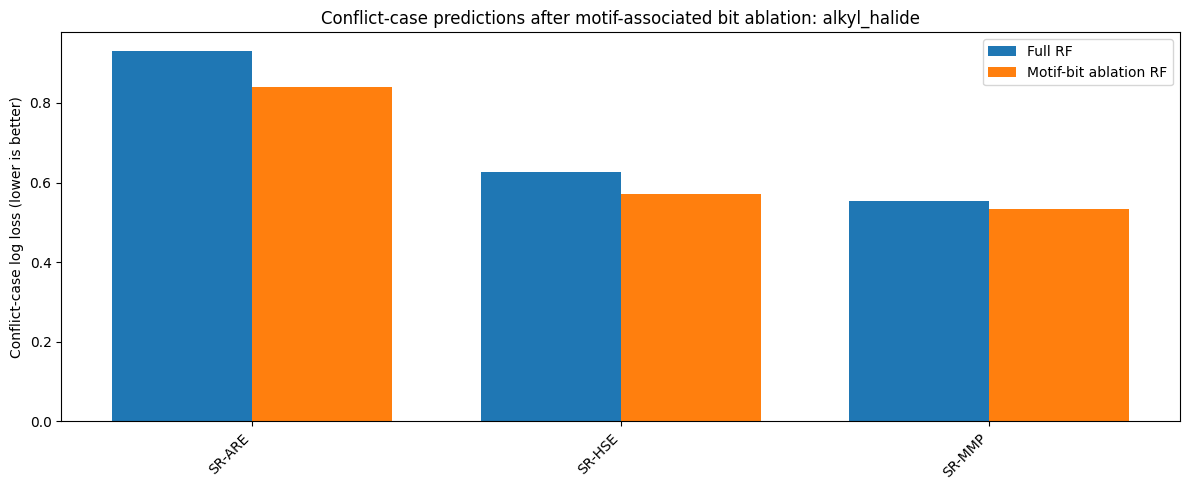

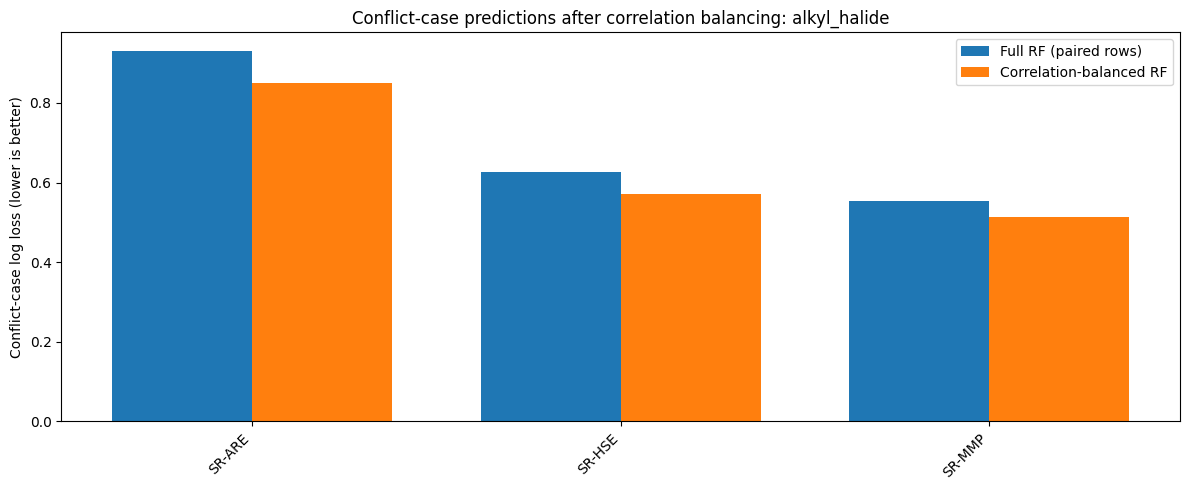

In [9]:
plot_mask = mitigation_results.dropna(subset=["conflict_logloss_full", "conflict_logloss_bit_ablation"]).copy()
if len(plot_mask):
    x = np.arange(len(plot_mask))
    width = 0.38
    plt.figure(figsize=(12, 5))
    plt.bar(x - width/2, plot_mask["conflict_logloss_full"], width, label="Full RF")
    plt.bar(x + width/2, plot_mask["conflict_logloss_bit_ablation"], width, label="Motif-bit ablation RF")
    plt.xticks(x, plot_mask["assay"], rotation=45, ha="right")
    plt.ylabel("Conflict-case log loss (lower is better)")
    plt.title(f"Conflict-case predictions after motif-associated bit ablation: {target}")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("No eligible conflict cases for the bit-ablation plot.")

plot_bal = mitigation_results.dropna(subset=["conflict_logloss_full_on_balanced_paired", "conflict_logloss_balanced"]).copy()
if len(plot_bal):
    x = np.arange(len(plot_bal))
    width = 0.38
    plt.figure(figsize=(12, 5))
    plt.bar(x - width/2, plot_bal["conflict_logloss_full_on_balanced_paired"], width, label="Full RF (paired rows)")
    plt.bar(x + width/2, plot_bal["conflict_logloss_balanced"], width, label="Correlation-balanced RF")
    plt.xticks(x, plot_bal["assay"], rotation=45, ha="right")
    plt.ylabel("Conflict-case log loss (lower is better)")
    plt.title(f"Conflict-case predictions after correlation balancing: {target}")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("No eligible paired conflict cases for the correlation-balancing plot.")

## 10. How to decide what the results mean

### Evidence consistent with shortcut-related brittleness

The case for follow-up is stronger if several things occur together:

1. The training folds repeatedly show a non-trivial motif–label association.
2. The full model has higher log loss or lower AUC on conflict cases than on agreement cases.
3. The full model beats the motif-only baseline on conflict cases by less than it does on agreement cases—or fails to improve on it at all.
4. Masking motif-associated fingerprint bits or correlation balancing improves held-out conflict-case log loss, with scaffold-clustered uncertainty supporting that improvement.
5. Overall AUC/log loss remain reasonably stable, rather than the intervention simply damaging all prediction quality.

### Results that would not support the claim

- A strong motif–label association alone is not shortcut learning.
- Strong within-motif AUC alone is not shortcut learning.
- An intervention that reduces overall performance without improving conflict performance is not a successful mitigation result.
- A bit-ablation result may partly reflect unrelated structures sharing hashed bit IDs; it should be followed by a chemically interpretable test.
- Results from the same Tox21 data after selecting alkyl halide from preliminary results are exploratory. Do not describe them as confirmatory evidence.

### What would make this more article-worthy

Repeat the finalized, predeclared protocol on an independent toxicity dataset or genuinely held-out endpoint; include a second model family (for example, a graph neural network); report all motif–assay results rather than only the best case; inspect chemically plausible matched examples; and account for multiple testing and scaffold/assay dependence. A stronger causal claim would need a chemically valid intervention or carefully matched comparisons, not only subgroup metrics.

## 11. Export the result tables

This cell writes the detailed tables to CSV next to the notebook so they can be inspected, plotted, or included in a report.

In [10]:
conflict_results.to_csv("tox21_motif_conflict_results.csv", index=False)
mitigation_results.to_csv("tox21_mitigation_comparison_results.csv", index=False)
bootstrap_results.to_csv("tox21_conflict_intervention_scaffold_bootstrap.csv", index=False)
predictions.to_csv("tox21_oof_predictions_motif_conflict.csv", index=False)
print("Saved:")
print(" - tox21_motif_conflict_results.csv")
print(" - tox21_mitigation_comparison_results.csv")
print(" - tox21_conflict_intervention_scaffold_bootstrap.csv")
print(" - tox21_oof_predictions_motif_conflict.csv")

Saved:
 - tox21_motif_conflict_results.csv
 - tox21_mitigation_comparison_results.csv
 - tox21_conflict_intervention_scaffold_bootstrap.csv
 - tox21_oof_predictions_motif_conflict.csv
